# 総研大 2024年度 講義「シミュレーション天文学」 / SOKEN-dai FY2024 Lecture Course: “Simulation Astronomy”
### 担当：馬場淳一 (国立天文台 科学研究部/鹿児島大学 天の川銀河研究センター) / Junichi Baba (D. of Science, NAOJ / Kagoshima University)

This code is provided for educational purposes only. Users are encouraged to utilize it at their own risk. I take no responsibility for any results obtained from research or analyses conducted using this code. It is essential to deepen your understanding and verify the results independently. Additionally, it is recommended to cross-reference with other reliable resources to ensure the appropriate methodologies are applied.

このコードは教育目的で提供されています。使用にあたっては、自己責任で行ってください。提供されたコードを基に行った研究や解析によって得られた結果について、私は一切の責任を負いません。使用する際には、必ず自身の理解を深め、結果を検証してください。また、他の信頼できるリソースと照らし合わせて、適切な方法論を選択することをお勧めします。

## 学習目標と計算上の前提

θは極角、φは方位角です。係数は Y_lm の複素共役で射影します。角積分はGauss–Legendre 48点×周期方位角96点を使用し、不連続な角分布には解像度の収束確認が必要です。dipole_distributionは符号付き基底テストであり正の物質密度ではありません。monopole_dipole_distributionは三軸楕円体ではなく単極＋双極の角分布です。有限のr_maxは外側密度を切り捨てます。

検証課題と判定基準は [演習ガイド](../docs/exercises.md) を参照してください。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.special import sph_harm_y
from scipy.integrate import dblquad
from scipy.integrate import quad
from functools import lru_cache

# Plot configuration parameters
parameters = {
    'axes.labelsize': 26,  # Set font size of x and y axis labels to 26
    'xtick.labelsize': 24,  # Set font size of x-axis ticks to 24
    'ytick.labelsize': 24,  # Set font size of y-axis ticks to 24
    'axes.titlesize': 24,   # Set font size of individual axis titles to 24
    'figure.titlesize': 24, # Set font size of the overall figure title to 24
    'legend.fontsize': 18,  # Set font size of the legend to 18
    'figure.figsize': [10, 6],  # Set default figure size to 10 inches by 6 inches
    'axes.linewidth': 2.0  # Set the line width of axis borders to 2.0
}

# Apply the parameters to matplotlib's default settings
plt.rcParams.update(parameters)

# Examples of Target Density Distributions

In [2]:
# Sphere Parameters
Rsph = 1.0  # Radius
rho0 = 1.0  # Density constant

# Conversion function from spherical to Cartesian coordinates (fixed radius r)
def spherical_to_cartesian(r, theta, phi):
    x = r * np.sin(theta) * np.cos(phi)
    y = r * np.sin(theta) * np.sin(phi)
    z = r * np.cos(theta)
    return x, y, z

# 1. Uniform Spherical Distribution (constant density inside radius R, zero outside)
def uniform_sphere(r, theta, phi, R=1.0):
    return np.where(r <= R, rho0, 0.0) * np.ones_like(theta)

# Potential calculation function for a uniformly dense sphere
def potential_uniform_sphere(r, theta, phi, R=1.0):
    M = (4/3) * np.pi * R**3 * rho0  # Mass of the sphere
    Phi_outside = -G * M / r
    Phi_inside = (2 * np.pi * G * rho0 / 3) * r**2 - 2 * np.pi * G * rho0 * R**2
    return np.where(r < R, Phi_inside, Phi_outside)

# 2. Gaussian radial shell (maximum at r=R)
def gaussian_sphere(r, theta, phi, R=1.0, sigma=0.2):
    return np.exp(-((r - R) ** 2) / (2 * sigma ** 2)) * np.ones_like(theta)

# 3. Plummer Sphere Density Distribution
def plummer_sphere(r, theta, phi, M=1.0, b=1.0):
    return (3 * M) / (4 * np.pi * b**3) * (1 + (r / b)**2)**(-5/2)

def potential_plummer_sphere(r, theta, phi, M=1.0, b=1.0):
    return -G * M / np.sqrt(r**2 + b**2)

# 4. Dipole Distribution (asymmetric distribution with angular dependence)
def dipole_distribution(r, theta, phi, R=1.0):
    return np.cos(theta) * np.where(r <= R, rho0, 0.0) * np.ones_like(theta)

# 5. Shell Distribution (density concentrated on the surface of the sphere)
def shell_distribution(r, theta, phi, R=1.0, thickness=0.1):
    return np.where((R - thickness / 2 <= r) & (r <= R + thickness / 2), rho0, 0.0) * np.ones_like(theta)

# 6. Torus Distribution (cylindrical density distribution)
def torus_distribution(r, theta, phi, R=1.0, radius=0.2):
    r_xy = r * np.sin(theta)
    return np.where((r_xy - R)**2 + (r * np.cos(theta))**2 <= radius**2, rho0, 0.0) * np.ones_like(theta)

# 7. Triaxial Distribution (3-axis asymmetric distribution)
def monopole_dipole_distribution(r, theta, phi, R=1.0, a=0.3, b=0.3, c=0.3):
    """
    a, b, c are parameters that adjust the strength of asymmetry.
    R is the effective radius of the distribution.
    """
    # Apply distribution only if radius r is less than or equal to R, otherwise 0
    condition = r <= R
    density = rho0 * (1 + a * np.sin(theta) * np.cos(phi) + 
                      b * np.sin(theta) * np.sin(phi) + 
                      c * np.cos(theta))
    return np.where(condition, density, 0.0) * np.ones_like(theta)

# Spherical Harmonic Expansions

This set of functions is designed to compute and reconstruct a scalar density field using **spherical harmonic expansions**. The spherical harmonics provide a natural way to represent functions on a sphere, and the coefficients for the expansion are calculated through numerical integration.

### Key Concepts:
- **Spherical Harmonics $ Y_{lm} $**: These are functions that represent the angular part of the solutions to Laplace's equation in spherical coordinates. They are used here to decompose and reconstruct the density distribution.
- **Density Function $ \rho(r, \theta, \phi) $**: A scalar function that defines how matter is distributed in a region of space.
- **Expansion in Spherical Harmonics**: The density function is expanded in terms of spherical harmonics, and the coefficients of this expansion are computed via integration.

### Functions:

### 1. **`compute_rho_lm(l, m, r, rho_func)`**
- **Purpose**: Computes the spherical harmonic coefficients $ \rho_{lm}(r) $, which are the projection of the density function onto the spherical harmonics.
- **Parameters**:
  - `l`: Degree of the spherical harmonic.
  - `m`: Order of the spherical harmonic.
  - `r`: Radial coordinate.
  - `rho_func`: The density function $ \rho(r, \theta, \phi) $.
- **Returns**: The real and imaginary parts of the spherical harmonic coefficient $ \rho_{lm}(r) $.
- **Process**:
  - The integrand is $ \rho(r, \theta, \phi) \cdot Y_{lm}^{*}(\theta, \phi) \cdot \sin(\theta) $, where $ Y_{lm} $ is the spherical harmonic.
  - Uses numerical integration (Gauss–Legendre quadrature and a periodic azimuthal sum) to compute the real and imaginary parts of the spherical harmonic coefficient.

### 2. **`reconstruct_density(l_max, r, theta, phi, rho_func)`**
- **Purpose**: Reconstructs the density function $ \rho(r, \theta, \phi) $ from its spherical harmonic expansion up to a maximum degree $ l_{\text{max}} $.
- **Parameters**:
  - `l_max`: Maximum degree $ l_{\text{max}} $ for the expansion.
  - `r`: Radial coordinate.
  - `theta`: Polar angle.
  - `phi`: Azimuthal angle.
  - `rho_func`: The density function $ \rho(r, \theta, \phi) $.
- **Returns**: The reconstructed density at the specified point $ (r, \theta, \phi) $.
- **Process**:
  - Loops through all degrees $ l $ and orders $ m $ to compute the real and imaginary parts of the spherical harmonic expansion and sums them up to reconstruct the density.

### 3. **`cached_compute_rho_lm(l, m, r, rho_func)`**
- **Purpose**: Optimizes the calculation of $ \rho_{lm}(r) $ by caching the results of `compute_rho_lm` to avoid repeated computation.
- **Parameters**:
  - `l`: Degree of the spherical harmonic.
  - `m`: Order of the spherical harmonic.
  - `r`: Radial coordinate.
- **Returns**: The cached values of the real and imaginary parts of $ \rho_{lm}(r) $.
- **Note**: This uses Python's `lru_cache` decorator to store previously computed values in memory.

### 4. **`reconstruct_density_cached(l_max, r, theta, phi, rho_func)`**
- **Purpose**: A modified version of `reconstruct_density` that uses cached values of $ \rho_{lm}(r) $ for improved efficiency.
- **Parameters**:
  - Same as `reconstruct_density`.
- **Returns**: The reconstructed density using cached spherical harmonic coefficients.
- **Process**:
  - Similar to `reconstruct_density`, but leverages cached values to speed up the reconstruction process.

### Key Steps in the Workflow:
1. **Compute Spherical Harmonic Coefficients**:
   - For each $ l $ and $ m $, the code calculates the projection of the density function onto the corresponding spherical harmonic using numerical integration.
   
2. **Reconstruct the Density**:
   - The density function is then reconstructed as a sum over the real and imaginary parts of the spherical harmonics, weighted by the previously computed coefficients.

3. **Optimize with Caching**:
   - The caching mechanism allows the program to store the results of expensive function evaluations, improving performance when reconstructing the density multiple times.

### Key Takeaways:
- **Spherical Harmonic Expansion**: This method provides a systematic way to decompose a density function into its angular components.
- **Numerical Integration**: The real and imaginary parts of the spherical harmonic coefficients are computed via numerical integration using Gauss–Legendre quadrature in cos(theta) and a periodic azimuthal sum.
- **Optimization with Caching**: Caching results in faster computations, especially when repeatedly evaluating the same harmonic coefficients.
- **Applications**: This approach can be applied to any scalar field that can be represented in spherical coordinates, making it useful in astrophysics, geophysics, and quantum mechanics.

In [3]:
# Calculate the real and imaginary parts of the spherical harmonic coefficients rho_{lm}(r)
@lru_cache(maxsize=16384)
def compute_rho_lm(l, m, r, rho_func, n_theta=48, n_phi=96):
    """Project density against conjugate Y_lm; refine quadrature for angular edges."""
    u, weights = np.polynomial.legendre.leggauss(n_theta)
    theta = np.arccos(u)[:, None]
    phi = (2 * np.pi * np.arange(n_phi) / n_phi)[None, :]
    values = rho_func(r, theta, phi) * np.conj(sph_harm_y(l, m, theta, phi))
    coefficient = np.sum(values * weights[:, None]) * (2 * np.pi / n_phi)
    return coefficient.real, coefficient.imag

# Reconstruct the density using spherical harmonic expansion
def reconstruct_density(l_max, r, theta, phi, rho_func):
    """
    Reconstructs rho(r, theta, phi) using an expansion in spherical harmonics Y_{lm} (both real and imaginary parts)
    rho_func: The density distribution function to use
    """
    rho_reconstructed = 0.0
    for l in range(0, l_max + 1):
        for m in range(-l, l + 1):
            rho_lm_real, rho_lm_imag = compute_rho_lm(l, m, r, rho_func)
            Y_lm = sph_harm_y(l, m, theta, phi)
            # Add the real and imaginary parts to reconstruct the density
            rho_reconstructed += rho_lm_real * Y_lm.real - rho_lm_imag * Y_lm.imag
    return rho_reconstructed

# Speed up compute_rho_lm using caching (optional)
@lru_cache(maxsize=None)
def cached_compute_rho_lm(l, m, r, rho_func):
    return compute_rho_lm(l, m, r, rho_func)

# Modified reconstruction function using cached_compute_rho_lm
def reconstruct_density_cached(l_max, r, theta, phi, rho_func):
    """
    Reconstructs rho(r, theta, phi) using an expansion in spherical harmonics Y_{lm} (both real and imaginary parts)
    rho_func: The density distribution function to use
    """
    rho_reconstructed = 0.0
    for l in range(0, l_max + 1):
        for m in range(-l, l + 1):
            rho_lm_real, rho_lm_imag = cached_compute_rho_lm(l, m, r, rho_func)
            Y_lm = sph_harm_y(l, m, theta, phi)
            # Add the real and imaginary parts to reconstruct the density
            rho_reconstructed += rho_lm_real * Y_lm.real - rho_lm_imag * Y_lm.imag
    return rho_reconstructed

### Objective:
This code generates visualizations for the spherical harmonic coefficients $ \rho_{lm}(r) $ of a given density function. It produces both a 3D plot of the original density distribution on a sphere and 2D plots showing the real and imaginary components of the spherical harmonic coefficients as functions of $ r $.

### Key Components:
1. **3D Plot of Density on a Sphere**:
   - The original density distribution $ \rho(r, \theta, \phi) $ is plotted on a 3D sphere in the first subplot.
   - The density values are normalized and mapped to colors using the `viridis` colormap, which is applied to the surface of the sphere.

2. **2D Plots of Spherical Harmonic Coefficients**:
   - For each $ l $ value (up to $ l_{\text{max}} $), separate 2D subplots are created to display the real and imaginary parts of $ \rho_{lm}(r) $.
   - These plots visualize how the spherical harmonic coefficients vary with $ r $.

### Functions:

### 1. **`compute_rho_lm(l, m, r, rho_func)`**:
   - Computes the spherical harmonic coefficients $ \rho_{lm}(r) $ by integrating the density function $ \rho(r, \theta, \phi) $ over $ \theta $ and $ \phi $, weighted by the complex conjugate of the spherical harmonics $ Y_{lm} $.
   - Returns the real and imaginary parts of the coefficient.

### 2. **`plot_rho_lm_by_l(l_max, r_min, r_max, num_points, rho_func)`**:
   - **Purpose**: Creates a set of subplots that visualize the spherical harmonic decomposition of the density function.
   - **Parameters**:
     - `l_max`: The maximum $ l $-value to use in the spherical harmonic expansion.
     - `r_min`, `r_max`: The range of $ r $-values for plotting the coefficients.
     - `num_points`: The number of points to evaluate along the $ r $-axis.
     - `rho_func`: The density function $ \rho(r, \theta, \phi) $ to be expanded in spherical harmonics.
   - **Process**:
     1. **3D Plot**: The first subplot shows a 3D representation of the density function $ \rho(r, \theta, \phi) $ on a sphere with radius 1. The density is mapped to colors using a colormap.
     2. **2D Plots**: For each $ l $ value (from 0 to $ l_{\text{max}} $), two subplots are created:
        - One for the real part of $ \rho_{lm}(r) $.
        - One for the imaginary part of $ \rho_{lm}(r) $.
     3. **Looping Over $ m $**: For each $ l $, the real and imaginary parts of $ \rho_{lm}(r) $ are computed for all $ m $ values from $ -l $ to $ l $. These values are plotted against $ r $.
     4. **Layout Adjustments**: The subplots are arranged in a grid, and the layout is adjusted for better spacing.

### Key Steps:

1. **3D Plot of Density**:
   - The density function is plotted on a unit sphere to visually represent how $ \rho(r, \theta, \phi) $ varies over the surface.
   - The density values are normalized to a colormap for better visualization.

2. **Real and Imaginary Plots**:
   - The real and imaginary parts of the spherical harmonic coefficients $ \rho_{lm}(r) $ are plotted as a function of $ r $ for different $ l $ and $ m $ values.
   - These plots help in understanding how the density function is decomposed into spherical harmonics.

### Key Takeaways:
- **Spherical Harmonic Decomposition**: The code decomposes a scalar density function into its spherical harmonic components, providing insights into the angular structure of the density distribution.
- **3D Visualization**: The 3D plot of the density distribution on a sphere allows for a visual understanding of the density variations across angles.
- **2D Coefficient Visualization**: The real and imaginary parts of the spherical harmonic coefficients give a detailed look at how the density is represented in terms of spherical harmonics for different $ l $ and $ m $ values.

In [4]:
def plot_rho_lm_by_l(l_max, r_min, r_max, num_points, rho_func):
    r_values = np.linspace(r_min, r_max, num_points)
    
    # Set the overall size of the graph (divided into 3 rows and l_max + 1 columns, panel (0,0) is 3D, others are 2D)
    size = 8
    fig, axes = plt.subplots(3, l_max + 1, figsize=(size*(l_max + 1), 3*size))
    for i in range(3):
        for j in range(l_max + 1):
            ax = axes[i, j]
            ax.set_visible(False)   
    
    # 3D plot of the original density distribution rho(r,theta,phi) in panel (0,0)
    ax_3d = fig.add_subplot(3, l_max + 1, 1, projection='3d')  # 3D plot in panel (0,0)
    r_sphere = 1.0  # Radius
    theta_vals = np.linspace(0, np.pi, 50)
    phi_vals = np.linspace(0, 2 * np.pi, 50)
    theta, phi = np.meshgrid(theta_vals, phi_vals)
    x, y, z = spherical_to_cartesian(r_sphere, theta, phi)
    rho_values = rho_func(r_sphere, theta, phi)
    # Represent the density on the sphere surface with color
    rho_values_normalized = (rho_values - np.min(rho_values)) / (np.max(rho_values) - np.min(rho_values) + 1e-10)  # Avoid division by zero
    rho_values_normalized = plt.cm.viridis(rho_values_normalized)  # Apply colormap
    # A 2D array is required for facecolors
    ax_3d.plot_surface(x, y, z, facecolors=rho_values_normalized, rstride=1, cstride=1, antialiased=True)
    ax_3d.set_title("3D Density Distribution")
    ax_3d.set_xlabel("X")
    ax_3d.set_ylabel("Y")
    ax_3d.set_zlabel("Z")
    ax_3d.set_box_aspect([1, 1, 1])

    ymin = -1.0
    ymax = +4.0
    xticks = np.arange(r_min, r_max + 0.1, 0.5)
    yticks = np.arange(ymin, ymax + 0.1, 0.5)

    '''
    # Plot the original density distribution rho(r) in panel (0,1)
    ax = axes[0, 1]
    ax.set_visible(True)
    rho_values_1d = [rho_func(r, 0, 0) for r in r_values]  # Calculated at theta=0, phi=0
    ax.plot(r_values, rho_values_1d, label=r"$\rho(r)$", lw=3)
    ax.set_xlabel("r")
    ax.set_ylabel(r"$\rho(r)$")
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)
    ax.set_xlim(0, r_max)
    ax.set_ylim(ymin, ymax)
    ax.legend(loc="upper right")
    ax.grid(True)
    '''
    
    # Create individual panels for plotting the real and imaginary parts of rho_{lm}(r) for each l
    for l in range(0, l_max + 1):
        real_ax = axes[1, l]  # Row for plotting the real part
        imag_ax = axes[2, l]  # Row for plotting the imaginary part
        real_ax.set_visible(True)
        imag_ax.set_visible(True)
        
        # Set x-axis and y-axis ticks at intervals of 0.5
        real_ax.set_xticks(xticks)
        real_ax.set_yticks(yticks)
        imag_ax.set_xticks(xticks)
        imag_ax.set_yticks(yticks)
        real_ax.set_xlim(0, r_max)
        real_ax.set_ylim(ymin, ymax)
        imag_ax.set_xlim(0, r_max)
        imag_ax.set_ylim(ymin, ymax)
        
        for m in range(-l, l + 1):
            rho_lm_real_values = [compute_rho_lm(l, m, r, rho_func)[0] for r in r_values]  # Real part
            rho_lm_imag_values = [compute_rho_lm(l, m, r, rho_func)[1] for r in r_values]  # Imaginary part

            real_ax.plot(r_values, rho_lm_real_values, label=f"$\\rho_{{{l},{m}}}^{{real}}$", lw=3)
            imag_ax.plot(r_values, rho_lm_imag_values, label=f"$\\rho_{{{l},{m}}}^{{imag}}$", lw=3)

        real_ax.set_xlabel("r")
        real_ax.set_ylabel("$\\rho_{lm}^{real}(r)$")
        real_ax.legend(loc="upper right")
        real_ax.grid(True)

        imag_ax.set_xlabel("r")
        imag_ax.set_ylabel("$\\rho_{lm}^{imag}(r)$")
        imag_ax.legend(loc="upper right")
        imag_ax.grid(True)
        
    plt.subplots_adjust(hspace=0.2, wspace=0.3)
    plt.show()

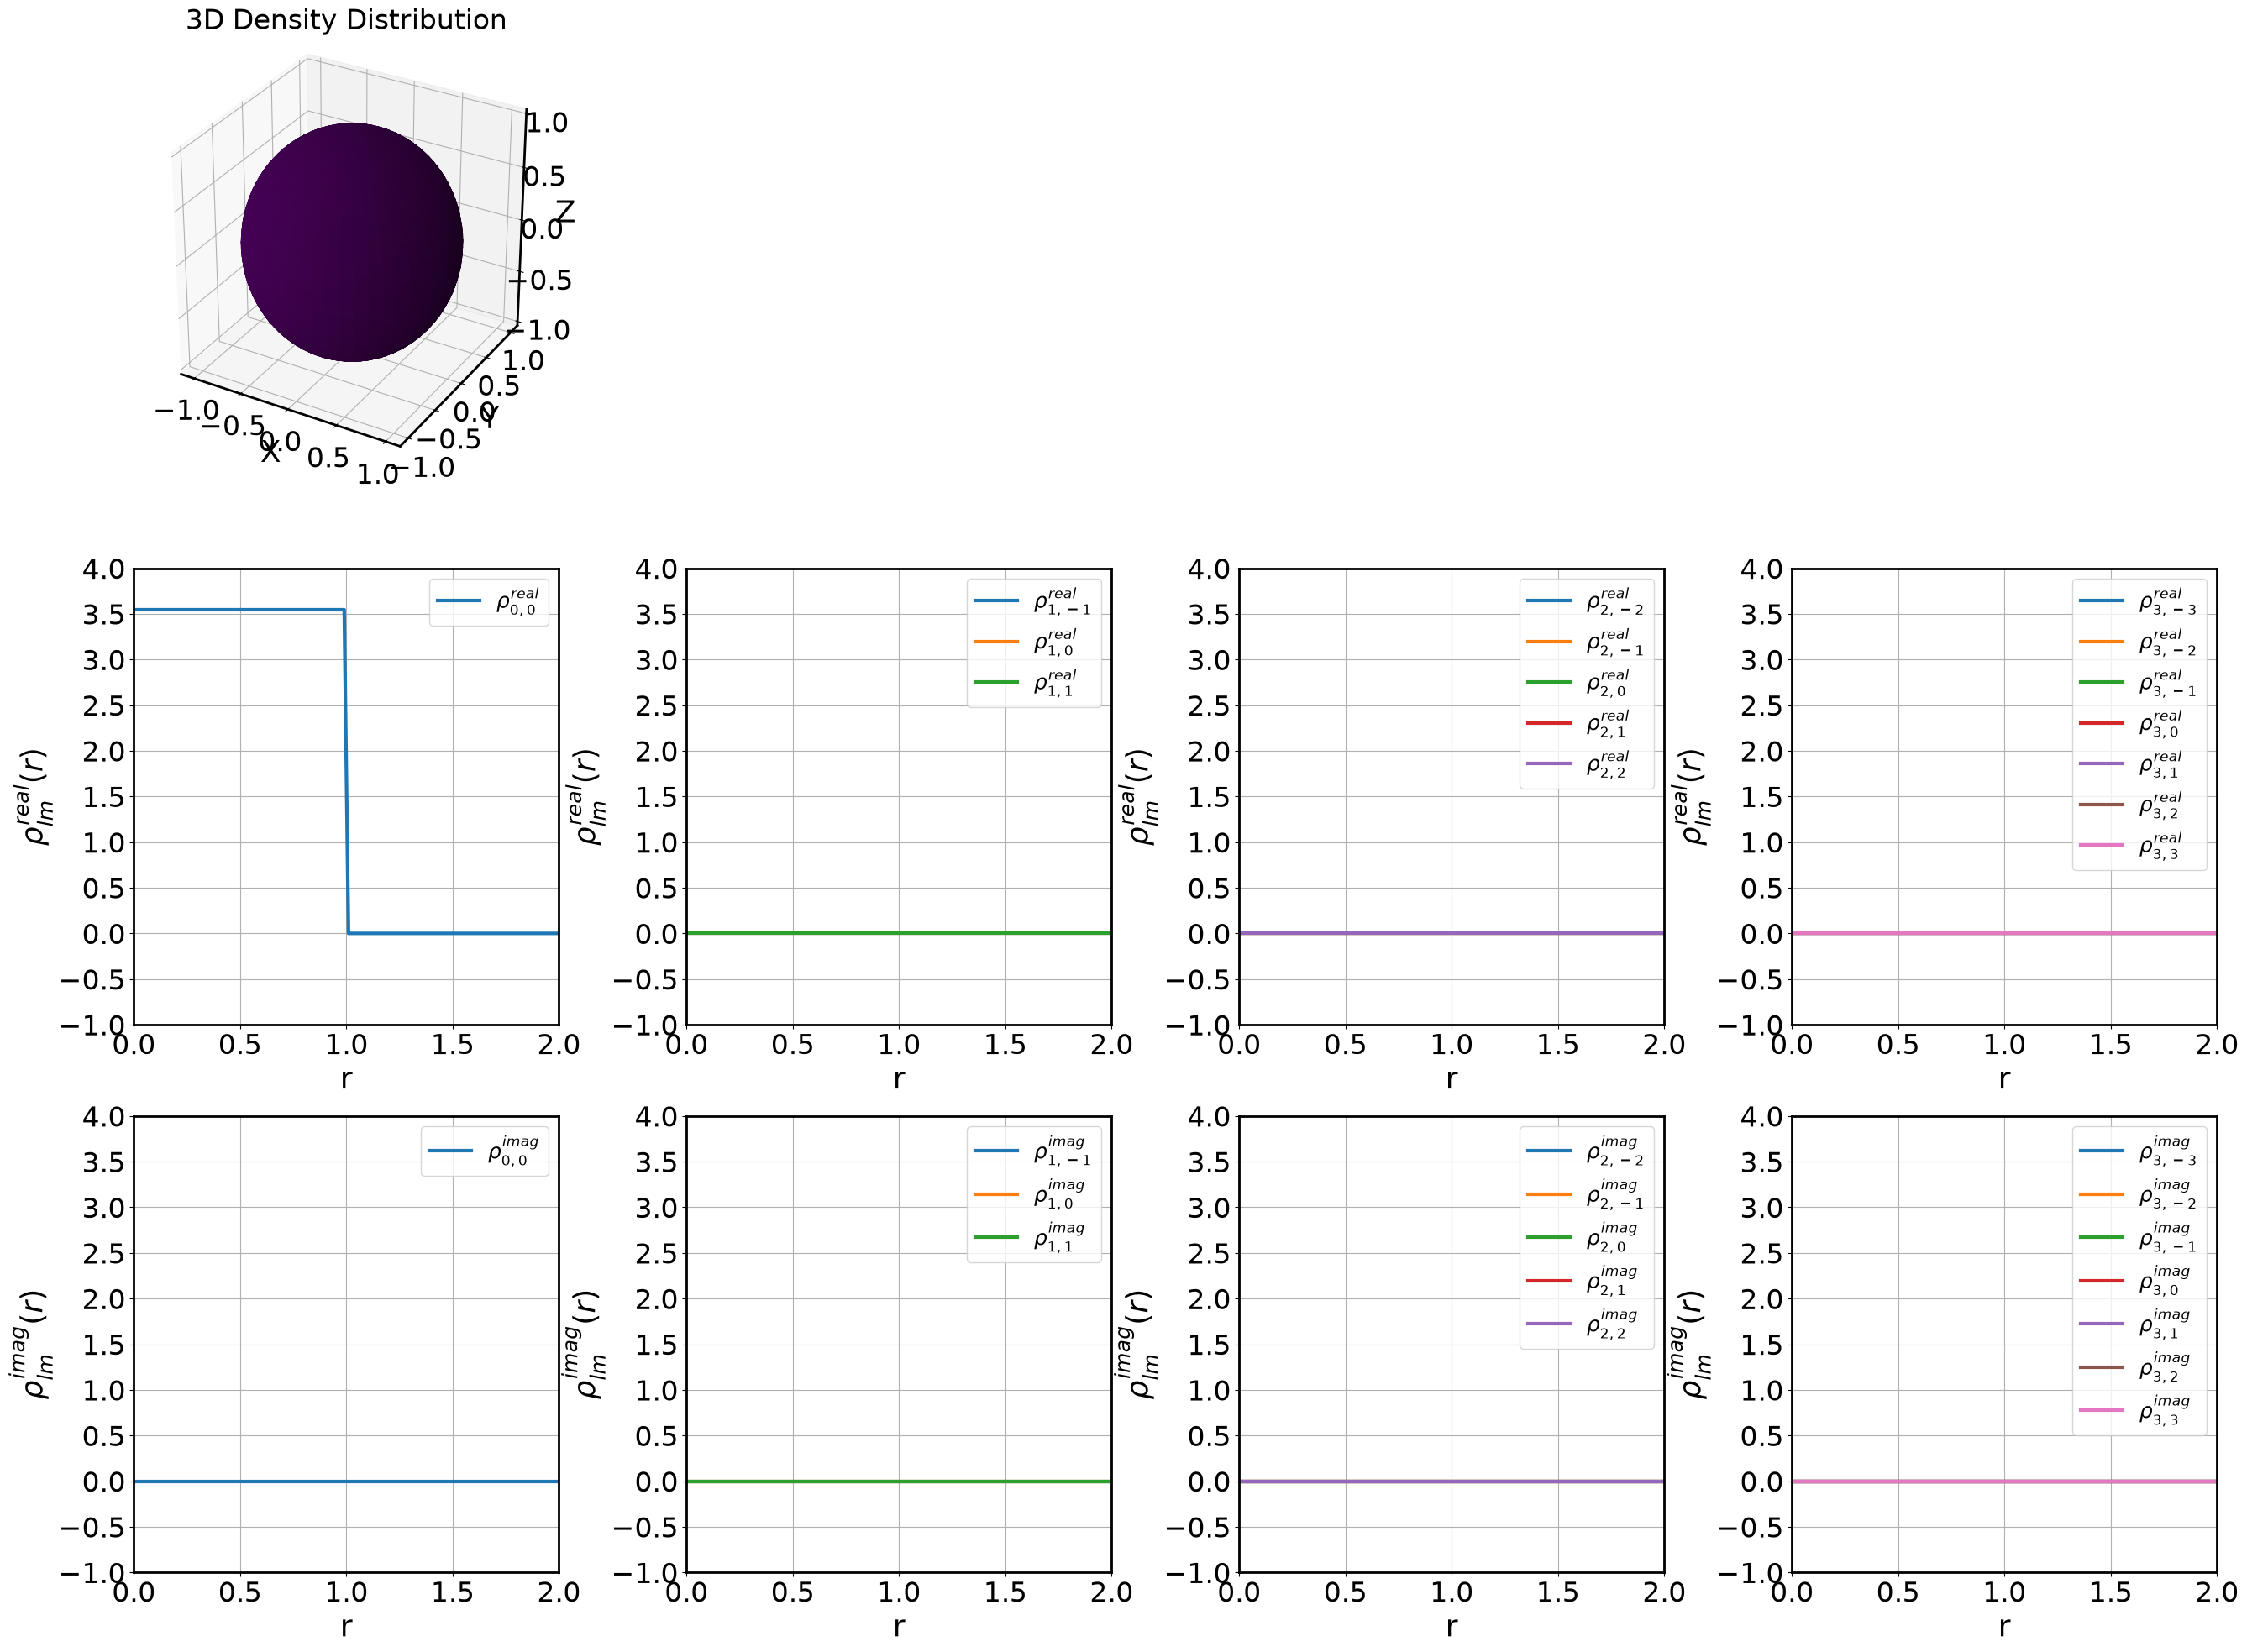

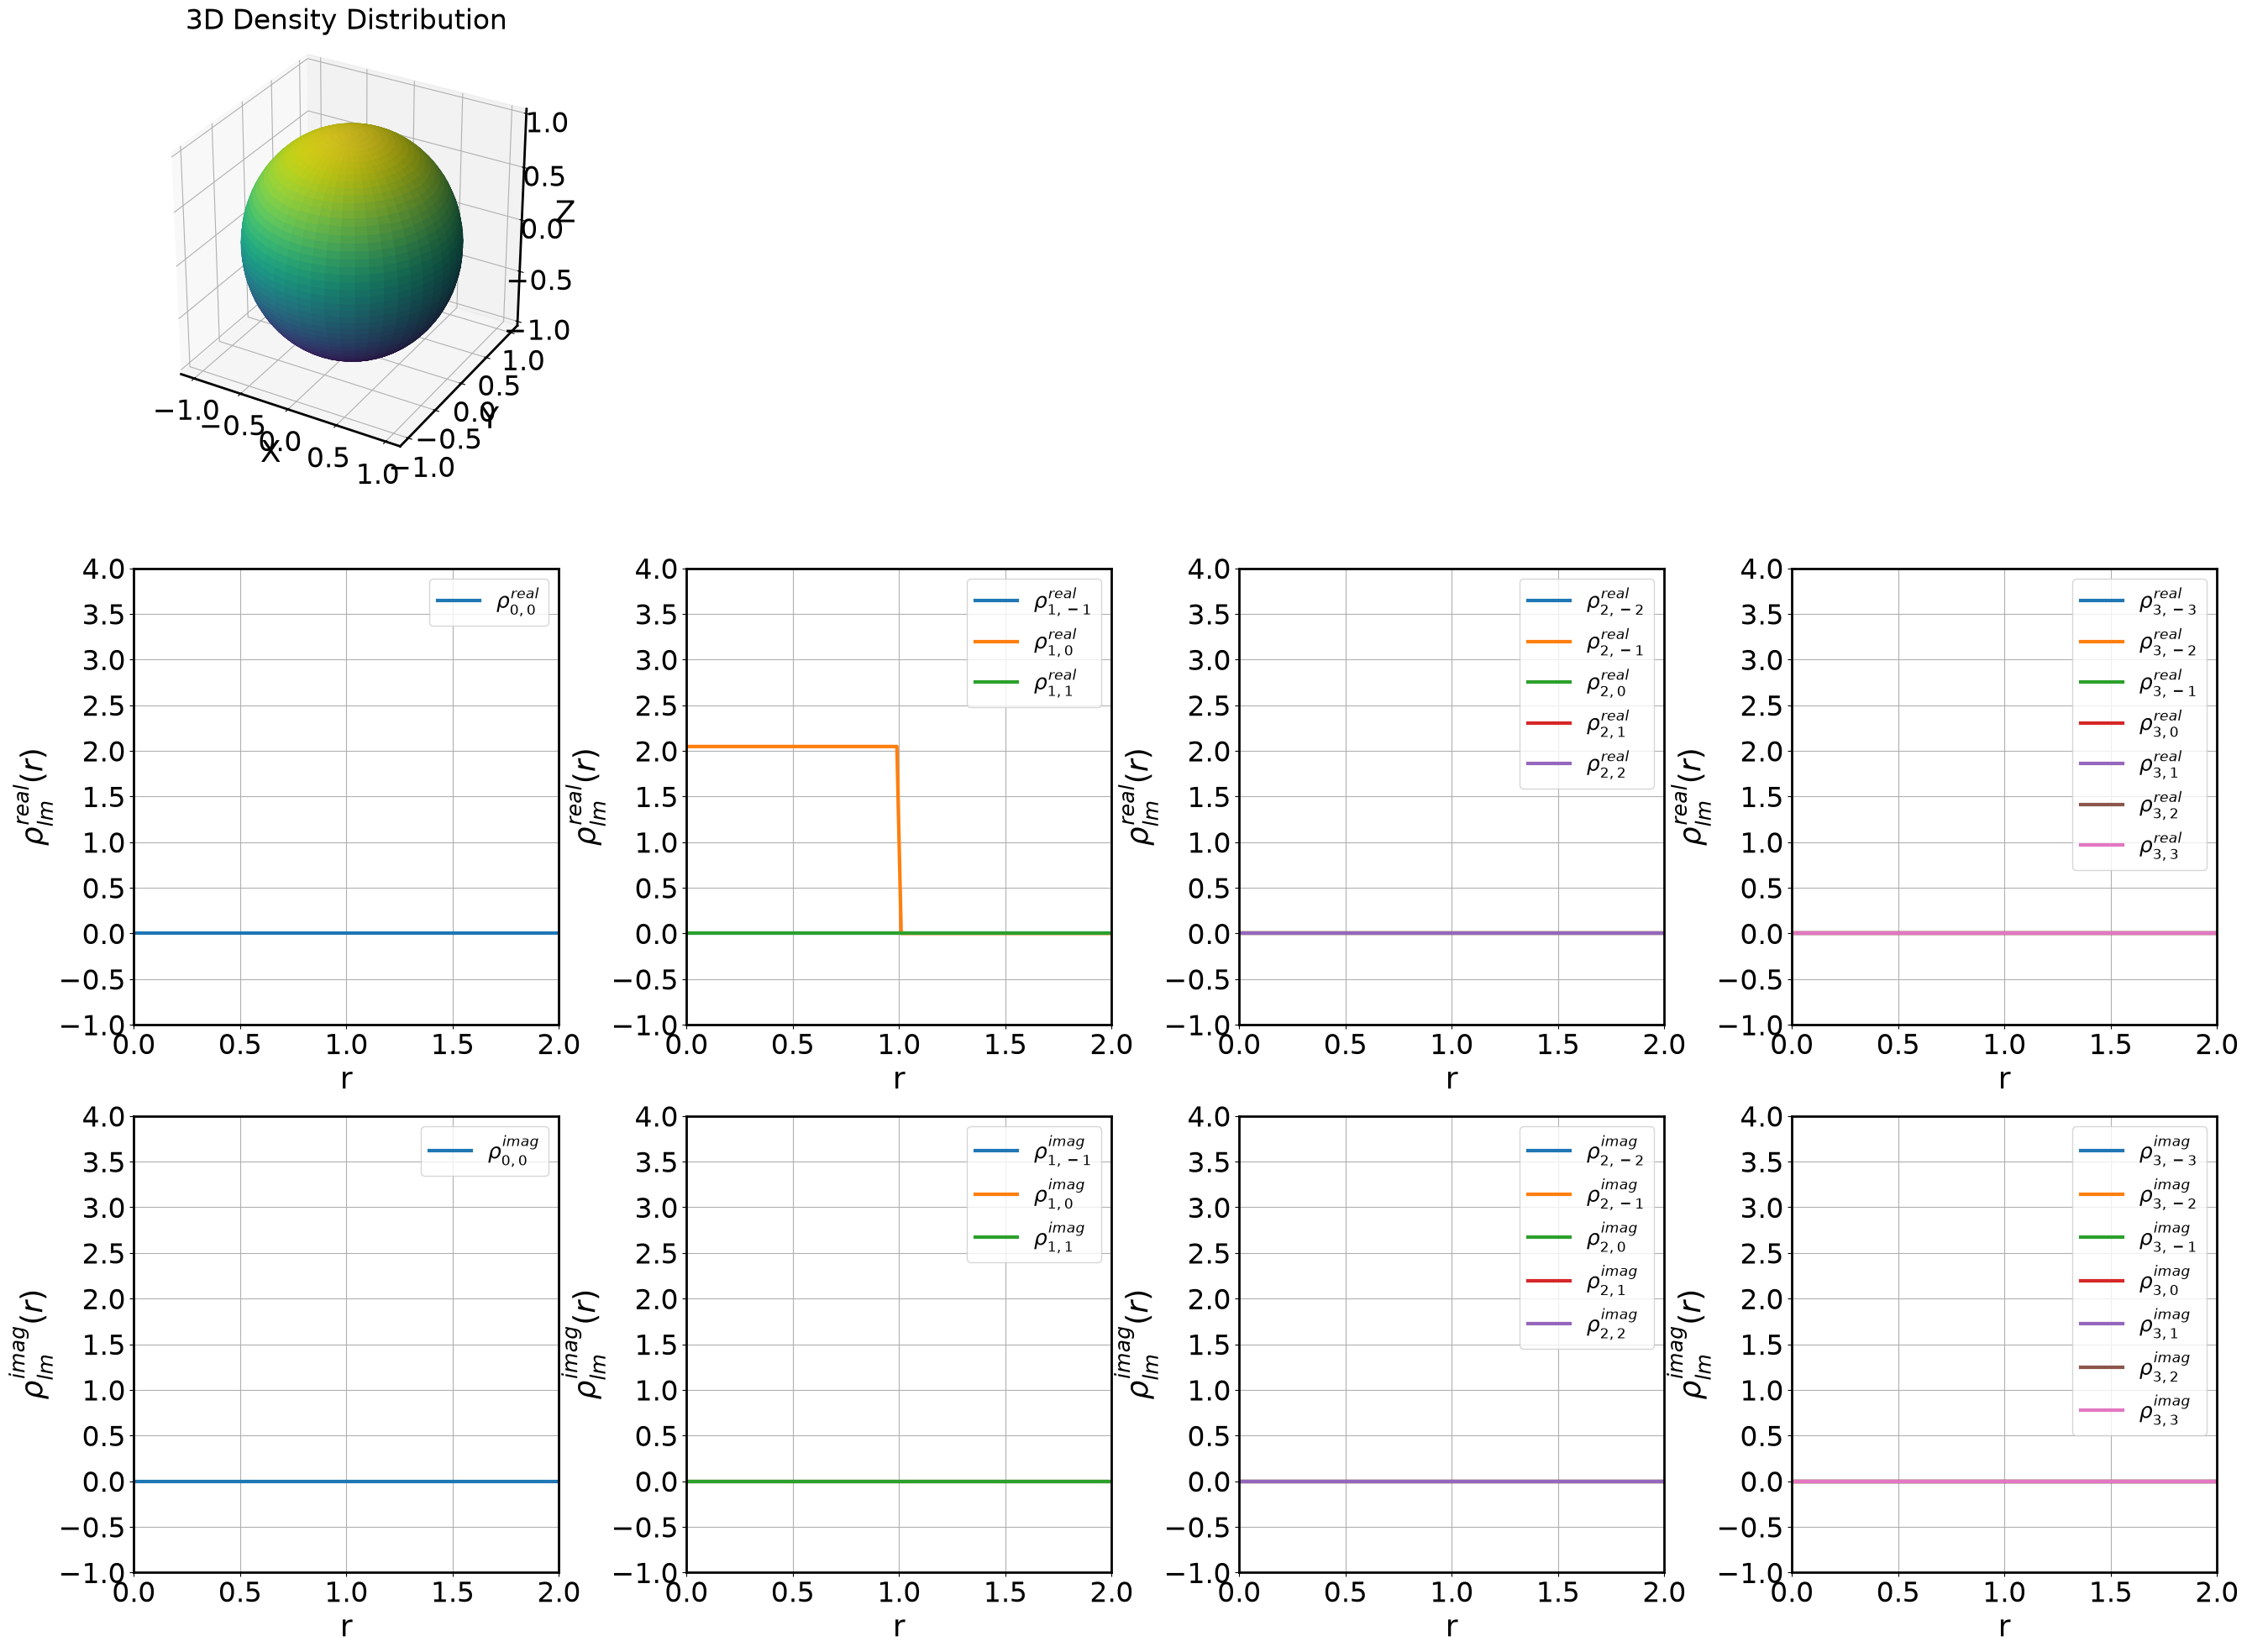

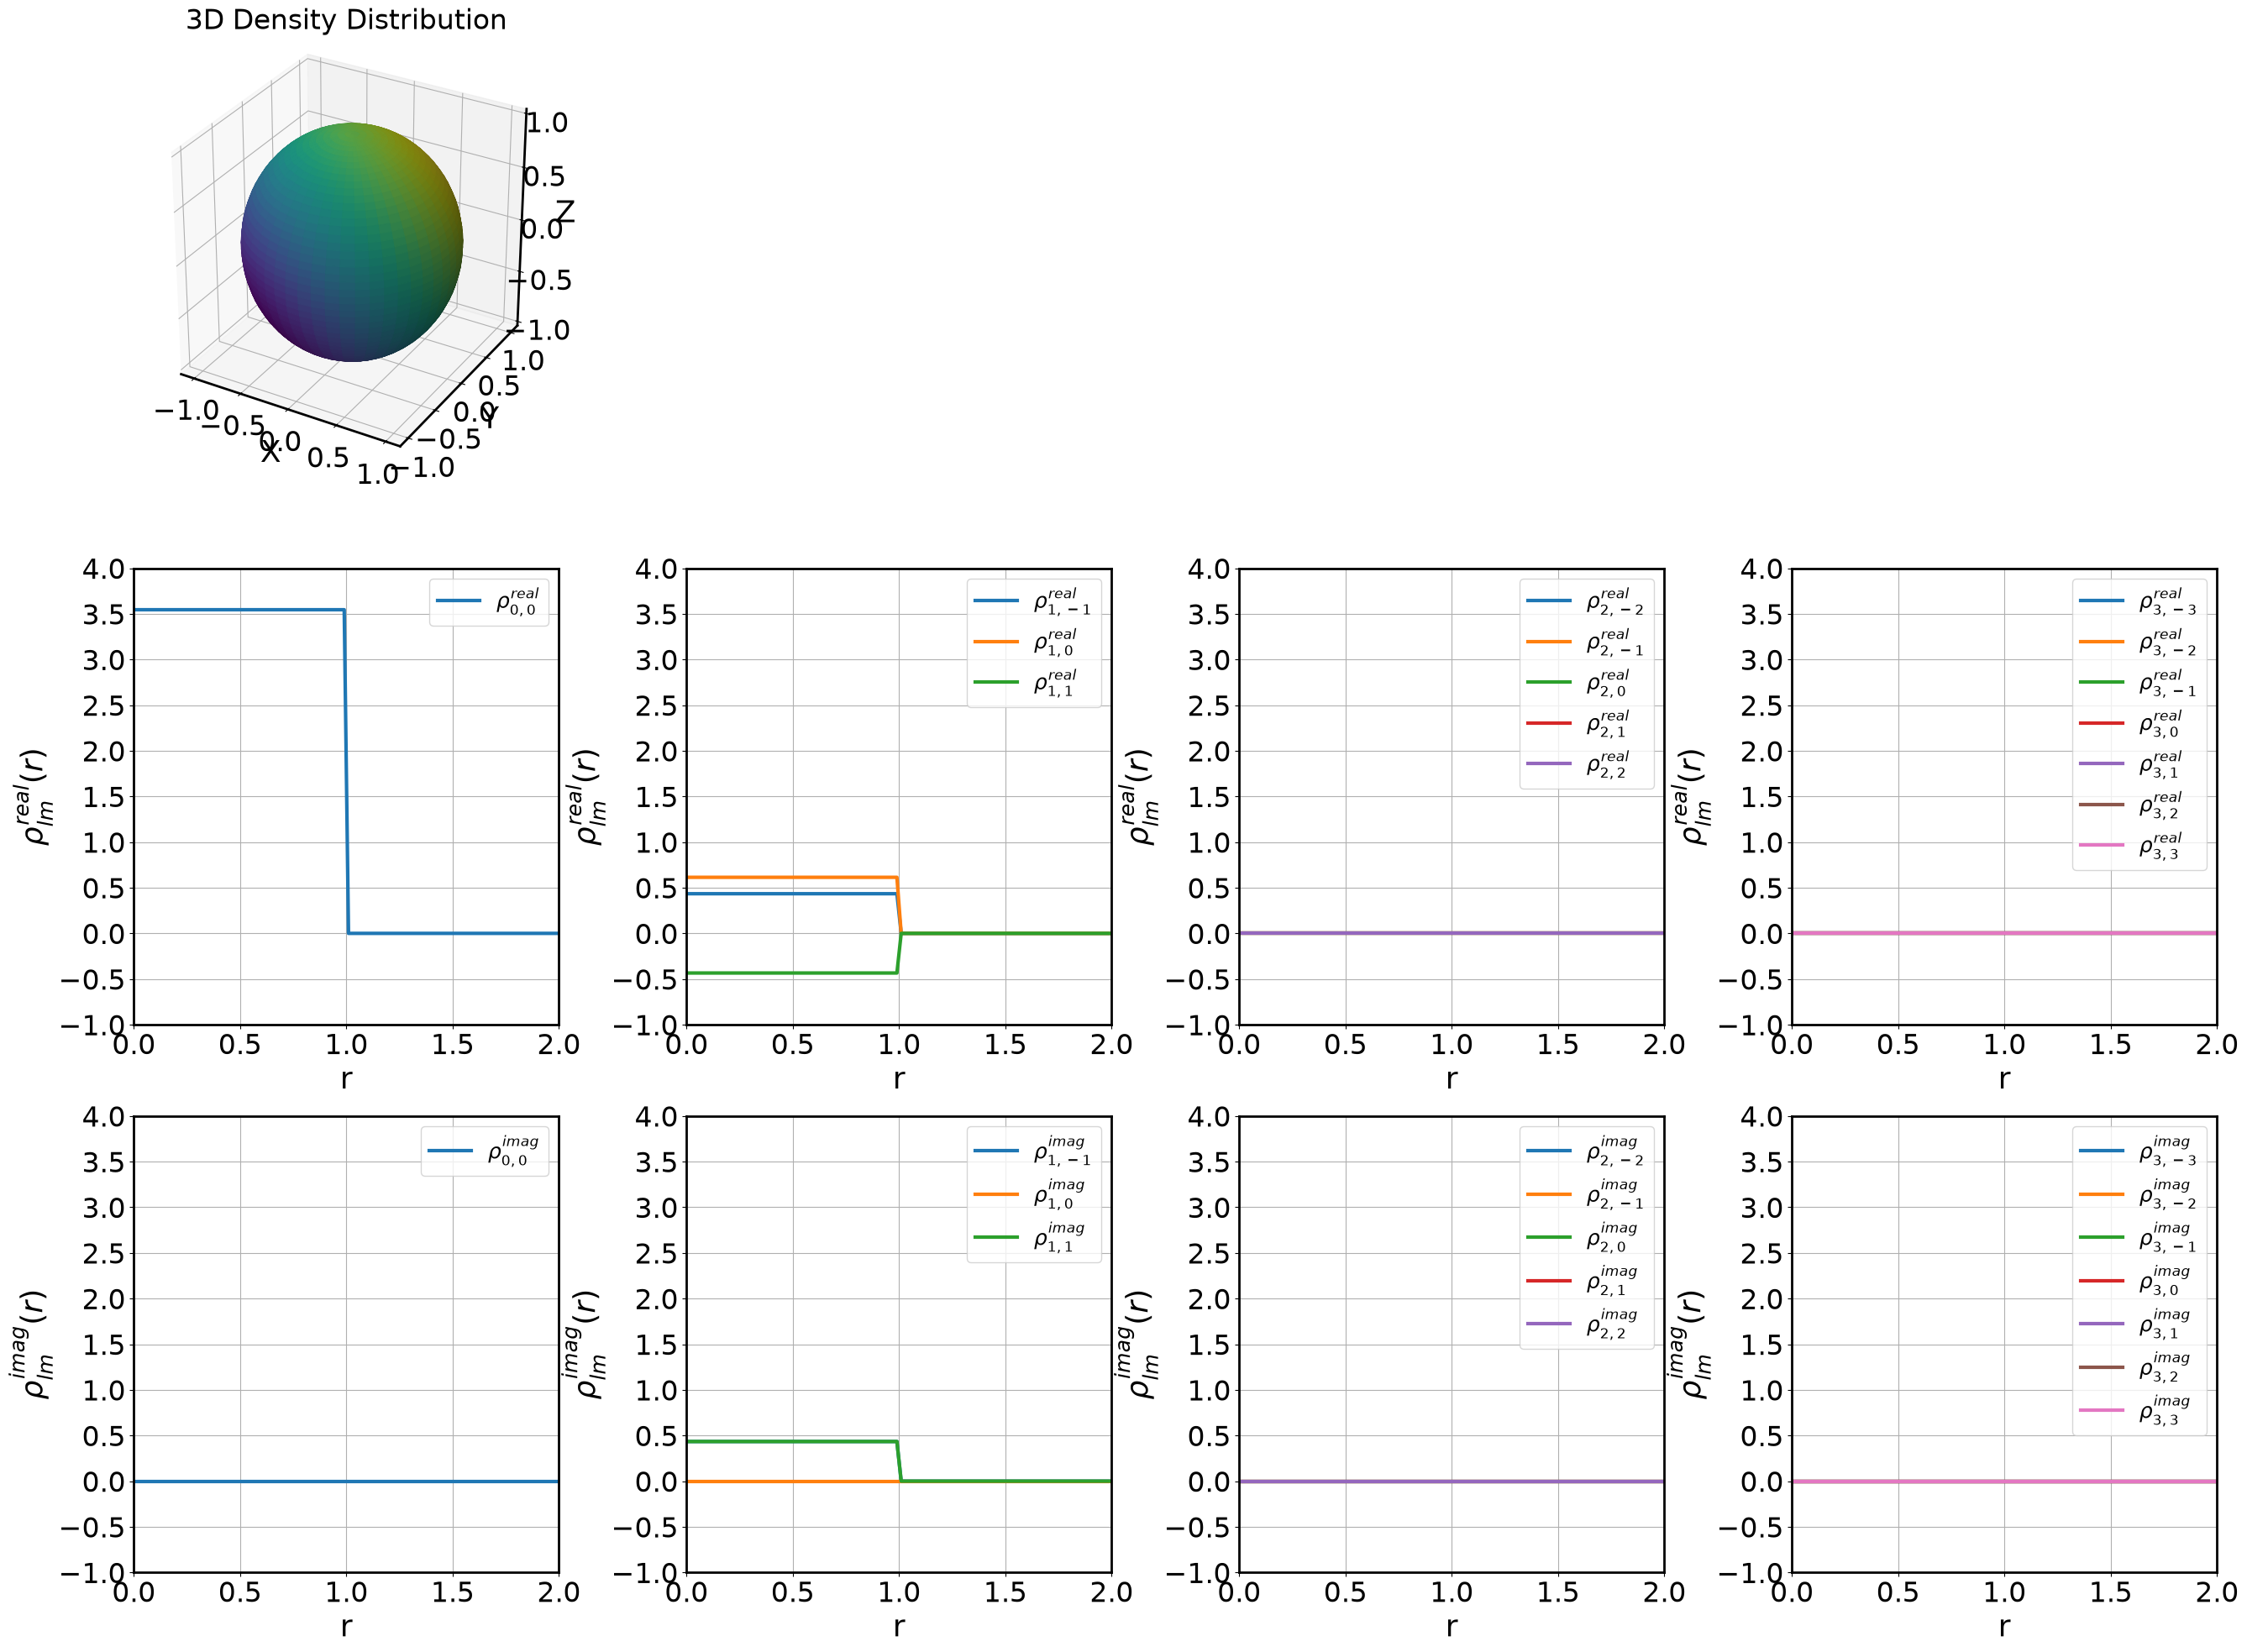

In [5]:
plot_rho_lm_by_l(l_max=3, r_min=0, r_max=2, num_points=100, rho_func=uniform_sphere)
#plot_rho_lm_by_l(l_max=3, r_min=0, r_max=2, num_points=100, rho_func=gaussian_sphere)
#plot_rho_lm_by_l(l_max=3, r_min=0, r_max=2, num_points=100, rho_func=inverse_square_law)
plot_rho_lm_by_l(l_max=3, r_min=0, r_max=2, num_points=100, rho_func=dipole_distribution)
#plot_rho_lm_by_l(l_max=3, r_min=0, r_max=2, num_points=100, rho_func=shell_distribution)
#plot_rho_lm_by_l(l_max=3, r_min=0, r_max=2, num_points=100, rho_func=torus_distribution)
plot_rho_lm_by_l(l_max=3, r_min=0, r_max=2, num_points=100, rho_func=monopole_dipole_distribution)

## Explanation of the Code

### Objective:
The main goal of this code is to reconstruct a density distribution function $ \rho(r, \theta, \phi) $ using spherical harmonic expansions. By using cached computations for the spherical harmonic coefficients, the process becomes more efficient. The test function demonstrates how the reconstructed density can be calculated at a given point.

### Key Components:

1. **`reconstruct_density_with_cache` Function**:
   - This function reconstructs the density function $ \rho(r, \theta, \phi) $ at a specific point using a spherical harmonic expansion up to a given maximum order $ l_{\text{max}} $.
   - **Parameters**:
     - `l_max`: Maximum spherical harmonic degree $ l $ for the expansion.
     - `r`: Radial distance.
     - `theta`: Polar angle.
     - `phi`: Azimuthal angle.
     - `rho_func`: A function that describes the density distribution $ \rho(r, \theta, \phi) $.
   - **Process**:
     1. Loops over the spherical harmonic degrees $ l $ from 0 to $ l_{\text{max}} $.
     2. For each $ l $, loops over the orders $ m $ from $ -l $ to $ l $.
     3. Retrieves the cached values of the spherical harmonic coefficients $ \rho_{lm}(r) $ using the `cached_compute_rho_lm` function.
     4. Combines the real and imaginary parts of the spherical harmonics to reconstruct the density at $ (r, \theta, \phi) $.
   - **Returns**: The reconstructed density at the given point.

2. **`test` Function**:
   - A test function to verify the implementation of the spherical harmonic reconstruction.
   - **Parameters**:
     - `r`: Radial distance for the test case (set to 0.5).
     - `theta`: Polar angle $ \theta $, set to $ \pi/4 $.
     - `phi`: Azimuthal angle $ \phi $, set to $ \pi/3 $.
     - `l_max`: Maximum spherical harmonic degree $ l $, set to 5.
   - **Process**:
     1. Defines a simple density function where $ \rho = 1 $ if $ r \leq 1 $, otherwise $ \rho = 0 $.
     2. Calls the `reconstruct_density_with_cache` function to calculate the reconstructed density at the given point.
     3. Prints the result in scientific notation to verify the accuracy of the reconstruction.

### Key Features:

1. **Caching for Efficiency**:
   - The `cached_compute_rho_lm` function stores previously computed spherical harmonic coefficients. This reduces redundant calculations, significantly improving performance when reconstructing the density for multiple points or when the same $ l $, $ m $, and $ r $ values are reused.

2. **Spherical Harmonic Expansion**:
   - The density function $ \rho(r, \theta, \phi) $ is reconstructed by summing the spherical harmonic coefficients $ \rho_{lm}(r) $ weighted by the spherical harmonics $ Y_{lm}(\theta, \phi) $. Both the real and imaginary parts of the coefficients are used.

3. **Testing and Validation**:
   - The `test` function provides a simple use case with a uniform density function inside a unit sphere. This helps validate that the spherical harmonic reconstruction works correctly by outputting the reconstructed density at a specific point.

### Key Takeaways:
- **Efficiency Through Caching**: Caching the spherical harmonic coefficients enhances performance, making the reconstruction process faster for repeated evaluations.
- **Accurate Density Reconstruction**: By using spherical harmonics, the code provides a flexible and accurate way to approximate a density function in spherical coordinates.
- **Modularity and Reusability**: The code is designed to be easily adaptable, allowing changes to the density function, expansion order $ l_{\text{max}} $, or evaluation points without altering the core structure.

In [6]:
# Version using cache in the reconstruction function
def reconstruct_density_with_cache(l_max, r, theta, phi, rho_func):
    """
    Reconstructs rho(r, theta, phi) using an expansion in spherical harmonics Y_{lm} (both real and imaginary parts).
    rho_func: The density distribution function to use.
    """
    rho_reconstructed = 0.0
    for l in range(0, l_max + 1):
        for m in range(-l, l + 1):
            rho_lm_real, rho_lm_imag = cached_compute_rho_lm(l, m, r, rho_func)
            Y_lm = sph_harm_y(l, m, theta, phi)
            # Add the real and imaginary parts to reconstruct the density
            rho_reconstructed += rho_lm_real * Y_lm.real - rho_lm_imag * Y_lm.imag
    return rho_reconstructed
    
# Test function
def test():
    # Parameter settings
    r = 0.5  # Example radius (unit: arbitrary)
    theta = np.pi / 4  # Example angle theta (unit: radians)
    phi = np.pi / 3  # Example angle phi (unit: radians)
    l_max = 5  # Maximum l (order of spherical harmonic expansion)
    
    # Test density distribution function
    def rho_func_test(r, theta, phi):
        return 1.0 if r <= 1.0 else 0.0
    
    # Compute the reconstructed density distribution
    rho_rec = reconstruct_density_with_cache(l_max, r, theta, phi, rho_func_test)
    
    # Display the result
    print(f"Reconstructed rho_rec(r={r}, theta={theta}, phi={phi}) = {rho_rec:.5e}")

# Run the test
test()


Reconstructed rho_rec(r=0.5, theta=0.7853981633974483, phi=1.0471975511965976) = 1.00000e+00


## 密度の球面調和関数展開係数（多重極展開）から重力ポテンシャルを求める

## Explanation of the Code

### Objective:
The code aims to calculate the gravitational potential $ \Phi(r, \theta, \phi) $ derived from a given density distribution function $ \rho(r, \theta, \phi) $ using a spherical harmonic expansion. This method involves calculating spherical harmonic coefficients $ Q_{lm}(r) $ from the density, then using these coefficients to compute the gravitational potential.

### Key Components:

1. **`compute_Q_lm` Function**:
   - This function calculates the spherical harmonic coefficient $ Q_{lm}(r) $ from the density distribution $ \rho_{lm}(r) $.
   - **Parameters**:
     - `l`: Degree of the spherical harmonic function.
     - `m`: Order of the spherical harmonic function.
     - `r`: Position $ r $.
     - `rho_func`: The density distribution function $ \rho(r, \theta, \phi) $.
     - `r_max`: The maximum value for the radial distance $ r $, serving as an upper limit for the integral.
   - **Process**:
     1. **Inner integral** is computed from 0 to $ r $, which gives the contribution to the gravitational potential within radius $ r $.
     2. **Outer integral** is computed from $ r $ to $ r_{\text{max}} $, which accounts for contributions from mass outside $ r $.
     3. The real and imaginary parts of $ Q_{lm}(r) $ are computed separately using numerical integration.
   - **Returns**: The real and imaginary parts of $ Q_{lm}(r) $, which are later used in the gravitational potential calculation.

2. **`compute_Phi_lm_from_Q_lm` Function**:
   - This function computes the spherical harmonic expansion coefficient $ \Phi_{lm}(r) $ for the gravitational potential using the precomputed $ Q_{lm}(r) $.
   - **Parameters**:
     - `l`: Degree of the spherical harmonic function.
     - `m`: Order of the spherical harmonic function.
     - `r`: Radial distance.
     - `Q_lm_func`: A function that calculates $ Q_{lm}(r) $.
   - **Process**:
     1. $ Q_{lm}(r) $ is used to compute $ \Phi_{lm}(r) $ by multiplying it by a constant factor involving $ G $ (gravitational constant) and $ l $.
     2. The real and imaginary parts of $ \Phi_{lm}(r) $ are returned.
   - **Returns**: The real and imaginary parts of $ \Phi_{lm}(r) $, which contribute to the final gravitational potential.

3. **`compute_gravitational_potential` Function**:
   - This function calculates the full gravitational potential $ \Phi(r, \theta, \phi) $ using spherical harmonic expansion up to degree $ l_{\text{max}} $.
   - **Parameters**:
     - `l_max`: Maximum degree of spherical harmonic expansion.
     - `r`: Radial distance.
     - `theta`: Polar angle.
     - `phi`: Azimuthal angle.
     - `rho_func`: Density distribution function $ \rho(r, \theta, \phi) $.
     - `r_max`: Upper limit for radial distance used in integrals for computing $ Q_{lm}(r) $.
   - **Process**:
     1. Loops over all $ l $ and $ m $ values up to $ l_{\text{max}} $.
     2. Computes $ Q_{lm}(r) $, then uses it to compute $ \Phi_{lm}(r) $.
     3. Combines the real and imaginary parts of the spherical harmonic functions to compute the final gravitational potential at the specified position $ (r, \theta, \phi) $.
   - **Returns**: The gravitational potential $ \Phi(r, \theta, \phi) $ at the given point.

### Key Features:

1. **Gravitational Potential Calculation**:
   - The code computes the gravitational potential using spherical harmonic expansion, which allows the potential to be computed from arbitrary density distributions.

2. **Numerical Integration**:
   - Real and imaginary parts of the spherical harmonic coefficients are calculated separately using numerical integration (`quad`), with accuracy checked against analytic cases.

3. **Flexibility**:
   - The function is flexible and can handle different density distributions by changing the `rho_func` parameter. It also allows for different limits on radial distance through `r_max`.

4. **Spherical Harmonic Expansion**:
   - The potential is expanded in terms of spherical harmonics, allowing for an accurate representation of the potential in systems with spherical symmetry.

### Key Takeaways:
- **Efficient Calculation**: The code computes the gravitational potential in a systematic way using spherical harmonic expansion. This makes it scalable and efficient for complex systems.
- **Modular Design**: Each function is modular and performs a specific role, allowing for easy extension to other use cases.
- **Numerical Accuracy**: By integrating real and imaginary components separately, the code requires convergence checks in the calculation of the gravitational potential.

In [7]:
# 重力定数
G = 1.0

In [8]:
# Calculate Q_{lm}(r) from rho_{lm}(r)
def compute_Q_lm(l, m, r, rho_func, r_max):
    """
    Q_{lm}(r) = (1 / r^(l+1)) * ∫_0^r rho_{lm}(r') r'^(l+2) dr'
                + r^l * ∫_r^∞ rho_{lm}(r') r'^(1-l) dr'
    
    Parameters:
    - l: Degree of the spherical harmonic function
    - m: Order of the spherical harmonic function
    - r: Position r
    - rho_func: Density distribution function
    - r_max: Maximum value of r (upper limit)
    
    Returns:
    - Q_lm_real, Q_lm_imag: Real and imaginary parts of the expansion coefficient Q_{lm}(r) for gravitational potential
    """
    
    if not (0 < r <= r_max):
        raise ValueError("Require 0 < r <= r_max")
    # Inner integral (0, r) - Calculate real and imaginary parts separately
    def inner_integrand_real(r_prime):
        rho_lm_real, _ = compute_rho_lm(l, m, r_prime, rho_func)
        return rho_lm_real * r_prime**(l+2)

    def inner_integrand_imag(r_prime):
        _, rho_lm_imag = compute_rho_lm(l, m, r_prime, rho_func)
        return rho_lm_imag * r_prime**(l+2)
    
    # Outer integral (r, ∞) - Calculate real and imaginary parts separately
    def outer_integrand_real(r_prime):
        rho_lm_real, _ = compute_rho_lm(l, m, r_prime, rho_func)
        return rho_lm_real * r_prime**(1-l)

    def outer_integrand_imag(r_prime):
        _, rho_lm_imag = compute_rho_lm(l, m, r_prime, rho_func)
        return rho_lm_imag * r_prime**(1-l)
    
    # Compute inner integral
    inner_integral_real, _ = quad(inner_integrand_real, 0, r)
    inner_integral_imag, _ = quad(inner_integrand_imag, 0, r)
    
    # Compute outer integral
    outer_integral_real, _ = quad(outer_integrand_real, r, r_max)
    outer_integral_imag, _ = quad(outer_integrand_imag, r, r_max)

    # Compute real and imaginary parts of Q_{lm}(r)
    Q_lm_real = (1 / r**(l+1)) * inner_integral_real + r**l * outer_integral_real
    Q_lm_imag = (1 / r**(l+1)) * inner_integral_imag + r**l * outer_integral_imag
    
    return Q_lm_real, Q_lm_imag


# Compute Phi_{lm}(r) from Q_{lm}(r)
def compute_Phi_lm_from_Q_lm(l, m, r, Q_lm_func):
    """
    Phi_lm_real, Phi_lm_imag = (-4*pi*G/(2*l+1)) * Q_lm_real, Q_lm_imag
    Parameters:
    - l: Degree of the spherical harmonic function
    - m: Order of the spherical harmonic function
    - r: Position r
    - Q_lm_func: Function to calculate Q_{lm}(r)
    
    Returns:
    - Phi_lm_real, Phi_lm_imag: Real and imaginary parts of the expansion coefficient Phi_{lm}(r) for gravitational potential
    """
    
    # Get real and imaginary parts of Q_{lm}(r)
    Q_lm_real, Q_lm_imag = Q_lm_func(l, m, r)
    
    # Compute constant factor
    factor = -(4 * np.pi * G) / (2 * l + 1)
    
    # Compute real and imaginary parts of Phi_{lm}(r)
    Phi_lm_real = factor * Q_lm_real
    Phi_lm_imag = factor * Q_lm_imag
    
    return Phi_lm_real, Phi_lm_imag


# Function to calculate the gravitational potential Phi(r, theta, phi) using spherical harmonic expansion
def compute_gravitational_potential(l_max, r, theta, phi, rho_func, r_max):
    """
    Using spherical harmonic expansion, calculate the gravitational potential Phi(r, theta, phi)
    derived from the density distribution function rho(r, theta, phi) using the following formula:
    
    Phi(r, theta, phi) = ∑_l ∑_m [Phi_{lm}^{real}(r) * Re(Y_{lm}(theta, phi)) 
                                  - Phi_{lm}^{imag}(r) * Im(Y_{lm}(theta, phi))]
    
    Parameters:
    - l_max: Maximum degree of the spherical harmonic expansion (0 <= l <= l_max)
    - r: Radial position for calculation
    - theta: Polar angle (in radians)
    - phi: Azimuthal angle (in radians)
    - rho_func: Density distribution function rho(r, theta, phi)
    - r_max: Upper limit for integration used in calculating Q_{lm}
    
    Returns:
    - Phi(r, theta, phi): Gravitational potential at the specified position (r, theta, phi)
    
    Process:
    1. Compute rho_{lm}(r) from the density distribution rho_func, then calculate Q_{lm}(r).
    2. From Q_{lm}(r), compute Phi_{lm}(r), and use the real and imaginary parts of the spherical harmonic function Y_{lm}(theta, phi) 
       to add the terms contributing to the gravitational potential.
    3. Return the gravitational potential Phi(r, theta, phi).
    """
    
    Phi = 0.0  # Initialize gravitational potential
    
    # Loop over l and m to compute spherical harmonic expansion
    for l in range(0, l_max + 1):
        for m in range(-l, l + 1):
            # Function to calculate Q_{lm}(r)
            Q_lm_func = lambda l, m, r: compute_Q_lm(l, m, r, rho_func, r_max)
            
            # Calculate real and imaginary parts of Phi_{lm}(r)
            Phi_lm_real, Phi_lm_imag = compute_Phi_lm_from_Q_lm(l, m, r, Q_lm_func)
            
            # Calculate real and imaginary parts of the spherical harmonic function Y_{lm}(theta, phi)
            Y_lm = sph_harm_y(l, m, theta, phi)
            Y_lm_real = Y_lm.real
            Y_lm_imag = Y_lm.imag
            
            # Add terms contributing to the gravitational potential (real and imaginary parts)
            Phi += Phi_lm_real * Y_lm_real - Phi_lm_imag * Y_lm_imag
            
    return Phi

In [9]:
# Example: Calculate the gravitational potential for a uniform density distribution
r = 1.0
theta = np.pi / 4
phi = np.pi / 3
l_max = 2
r_max = 10.0

Phi = compute_gravitational_potential(l_max, r, theta, phi, uniform_sphere, r_max)
print(f"Gravitational Potential at (r={r}, theta={theta}, phi={phi}) = {Phi:.5e}")

Gravitational Potential at (r=1.0, theta=0.7853981633974483, phi=1.0471975511965976) = -4.18879e+00


In [10]:
# Settings: l_max=2, calculate 20 points in the range [0.05, 2] for r
l_max = 2
r_min = 0.05
r_max = 2.0
num_points = 20

# Calculate the potential for each value of r
r_values = np.linspace(r_min, r_max, num_points)
Phi_uniform_values = []
Phi_plummer_values = []
for r in r_values:
    # Gravitational potential for a uniform density sphere (spherical harmonic expansion)
    Phi_uniform = compute_gravitational_potential(l_max, r, 0, 0, uniform_sphere, r_max=10.)
    Phi_uniform_values.append(Phi_uniform)
    
    # Gravitational potential for a Plummer sphere (spherical harmonic expansion)
    Phi_plummer = compute_gravitational_potential(l_max, r, 0, 0, plummer_sphere, r_max=10.)
    Phi_plummer_values.append(Phi_plummer)


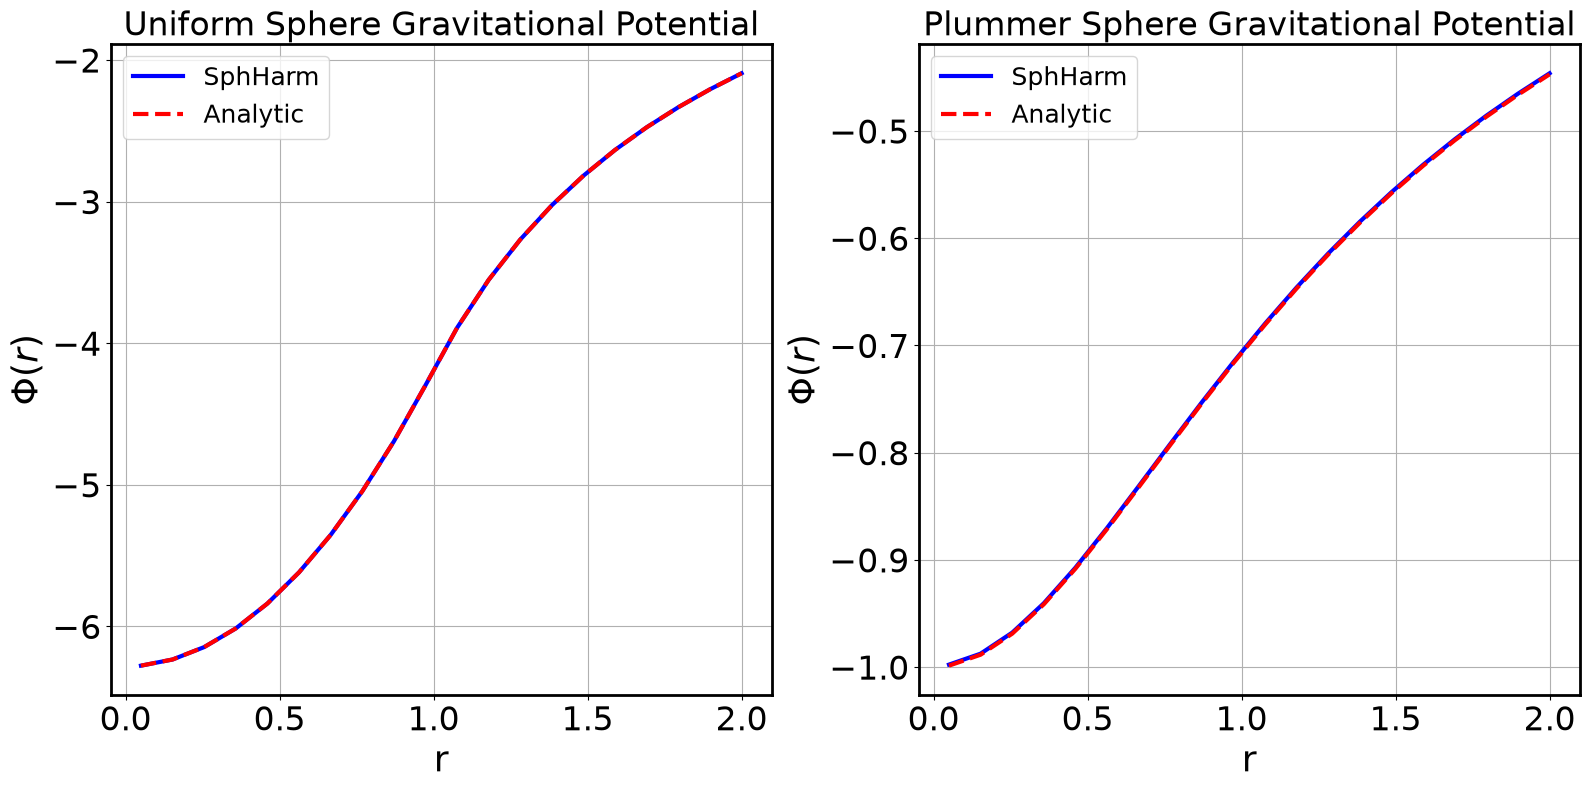

In [11]:
# Analytical solution for the uniform sphere
Phi_uniform_analytic = potential_uniform_sphere(r_values, 0, 0, R=1.0)

# Analytical solution for the Plummer sphere
Phi_plummer_analytic = potential_plummer_sphere(r_values, 0, 0, M=1.0, b=1.0)

# Plot side by side
size = 8
fig, axes = plt.subplots(1, 2, figsize=(2*size, size))

# Gravitational potential for the uniform sphere
axes[0].plot(r_values, Phi_uniform_values, label='SphHarm', color='b', lw=3)
axes[0].plot(r_values, Phi_uniform_analytic, label='Analytic', linestyle='--', color='r', lw=3)
axes[0].set_xlabel('r')
axes[0].set_ylabel('$\\Phi(r)$')
axes[0].set_title('Uniform Sphere Gravitational Potential')
axes[0].grid(True)
axes[0].legend()

# Gravitational potential for the Plummer sphere
axes[1].plot(r_values, Phi_plummer_values, label='SphHarm', color='b', lw=3)
axes[1].plot(r_values, Phi_plummer_analytic, label='Analytic', linestyle='--', color='r', lw=3)
axes[1].set_xlabel('r')
axes[1].set_ylabel('$\\Phi(r)$')
axes[1].set_title('Plummer Sphere Gravitational Potential')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()